# Sampling r with a Gaussian dust model

This guide simulates one multi-frequency data set at fiducial parameter values and runs the Gibbs sampler of `cmb_scattering.sampler` on it. It then looks at the chain: trace plots, the log-posterior over time, acceptance rates, autocorrelation, and the recovered parameter distributions against the truth.

The data model is the one of [`01_simulating_data.ipynb`](01_simulating_data.ipynb):

$$d_\nu = M_\nu B_\nu \,(f + a_\nu\, g) + n_\nu ,$$

with $f$ the CMB, $g$ the dust at 353 GHz, $a_\nu$ the dust frequency scaling and $n_\nu$ white noise.

## What is Gaussian here, and why it matters

Two separate Gaussian assumptions are made, and they should not be confused.

1. **The simulation is Gaussian. This is not physical.** The dust field is drawn as a Gaussian random field with a power-law spectrum. Real Galactic dust is strongly non-Gaussian: it is filamentary, its statistics vary across the sky, and its phases carry information that a power spectrum does not. The CMB lensing B-modes are also drawn as Gaussian, which they are not.
2. **The posterior is Gaussian. Here that is self-consistent.** The sampler's model for the dust is the same Gaussian field with the same power-law covariance that generated the data. The model is exactly right for these simulations, so the posterior should be unbiased and its width should be the true uncertainty.

Because of point 2, this notebook is a consistency check of the sampler and an optimistic baseline, not a forecast for real data. Applied to real, non-Gaussian dust (or to non-Gaussian simulations), the same Gaussian posterior is a misspecified model. It should in principle do worse: it ignores the non-Gaussian information that could help separate dust from a primordial signal, and its error bars and central values are no longer guaranteed to be right. Handling that case is the motivation for the scattering-transform statistics this package is being built toward.


## Simulating the data

The fiducial values are the sampler's defaults (`DEFAULT_TRUE_PARAMS`): BK18's dust amplitude and frequency exponent ([BICEP/Keck XIII](https://arxiv.org/abs/2110.00483)), Planck's dust slopes and BB/EE ratio ([Planck 2018 XI](https://arxiv.org/abs/1801.04945)), and $r = 0.03$. The patch is 128 pixels of 20', about 43 degrees across, so that it reaches the low multipoles where the tensor signal lives.


In [1]:
import contextlib
import io
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from cmb_lensing.mcmc_diagnostics import autocorrelation, integrated_autocorrelation_time
from cmb_lensing.chain_analysis import product_moments, product_pdf
from cmb_scattering.simulate_dust import simulate_data
from cmb_scattering.sampler import (DEFAULT_TRUE_PARAMS, PARAM_ORDER, DEFAULT_PROPOSAL_WIDTHS,
                                    sample_gaussian_posterior)

#importing cmb_lensing.chain_analysis switches matplotlib to the file-only Agg backend,
#so switch back to drawing figures in the notebook
%matplotlib inline

nside = 128
theta_pix = 20.0
uk_arcmin = 3.0
map_seed = 0

true_params = dict(DEFAULT_TRUE_PARAMS)
sim = simulate_data(nside, theta_pix, map_seed, uk_arcmin = uk_arcmin, **true_params)

for name in PARAM_ORDER:
    print(f"{name:>20} = {true_params[name]:.4g}")

   dust_amplitude_ee = 8.302
   dust_amplitude_bb = 4.4
        dust_knee_ee = -0.42
        dust_knee_bb = -0.54
                   r = 0.03
  frequency_exponent = 1.49


## Running the sampler

Each iteration of `sample_gaussian_posterior` draws the CMB field given the dust field, draws the dust field given the CMB field, and then updates the six parameters one at a time with a 1D random-walk Metropolis step. The dust temperature is held fixed.

The chain is 1000 iterations long and starts at the true parameter values, with the dust field starting at zero. The proposal widths below were hand-tuned on this data set. The sampler prints the running acceptance rates as it goes; that output is captured here and the final rates are reported further down.


In [2]:
num_iterations = 1000
chain_seed = 1

#capture the per-iteration acceptance printout
with contextlib.redirect_stdout(io.StringIO()):
    sample_histories, acceptance_rates, logposterior_values = sample_gaussian_posterior(
        sim["data"], sim["noise_covariance"], sim["scalar_covariance"],
        sim["tensor_covariance"], sim["mask"], sim["beam"], true_params,
        proposal_widths = DEFAULT_PROPOSAL_WIDTHS, num_iterations = num_iterations,
        seed = chain_seed, frequencies = sim["frequencies"])

print(f"{num_iterations} iterations, {len(PARAM_ORDER)} sampled parameters")

1000 iterations, 6 sampled parameters


## Acceptance rates

For a one-dimensional random-walk Metropolis step on a Gaussian target, the most efficient proposal width is the one that accepts about 44 % of proposals. Narrower proposals are accepted more often but barely move; wider ones move far but are mostly rejected. The value comes from Gelman, Roberts & Gilks, [*Efficient Metropolis jumping rules*](https://sites.stat.columbia.edu/gelman/research/published/baystat5.pdf) (1996), who also give the better-known high-dimensional limit of 23.4 %, derived in Roberts, Gelman & Gilks, [*Weak convergence and optimal scaling of random walk Metropolis algorithms*](https://doi.org/10.1214/aoap/1034625254) (1997). Roberts & Rosenthal, [*Optimal scaling for various Metropolis-Hastings algorithms*](https://doi.org/10.1214/ss/1015346320) (2001), review these results and show that the efficiency is not very sensitive to the exact rate.

Each parameter here is updated on its own, so 44 % is the relevant target.


In [3]:
OPTIMAL_1D_ACCEPTANCE_RATE = 0.44

print(f"{'parameter':>20}  acceptance rate   (target {OPTIMAL_1D_ACCEPTANCE_RATE:.2f})")
for name in PARAM_ORDER:
    print(f"{name:>20}  {acceptance_rates[name]:.2f}")

           parameter  acceptance rate   (target 0.44)
   dust_amplitude_ee  0.46
   dust_amplitude_bb  0.48
        dust_knee_ee  0.39
        dust_knee_bb  0.40
                   r  0.45
  frequency_exponent  0.43


## Trace plots

The value of each parameter at every iteration, with the true value as a dashed line.


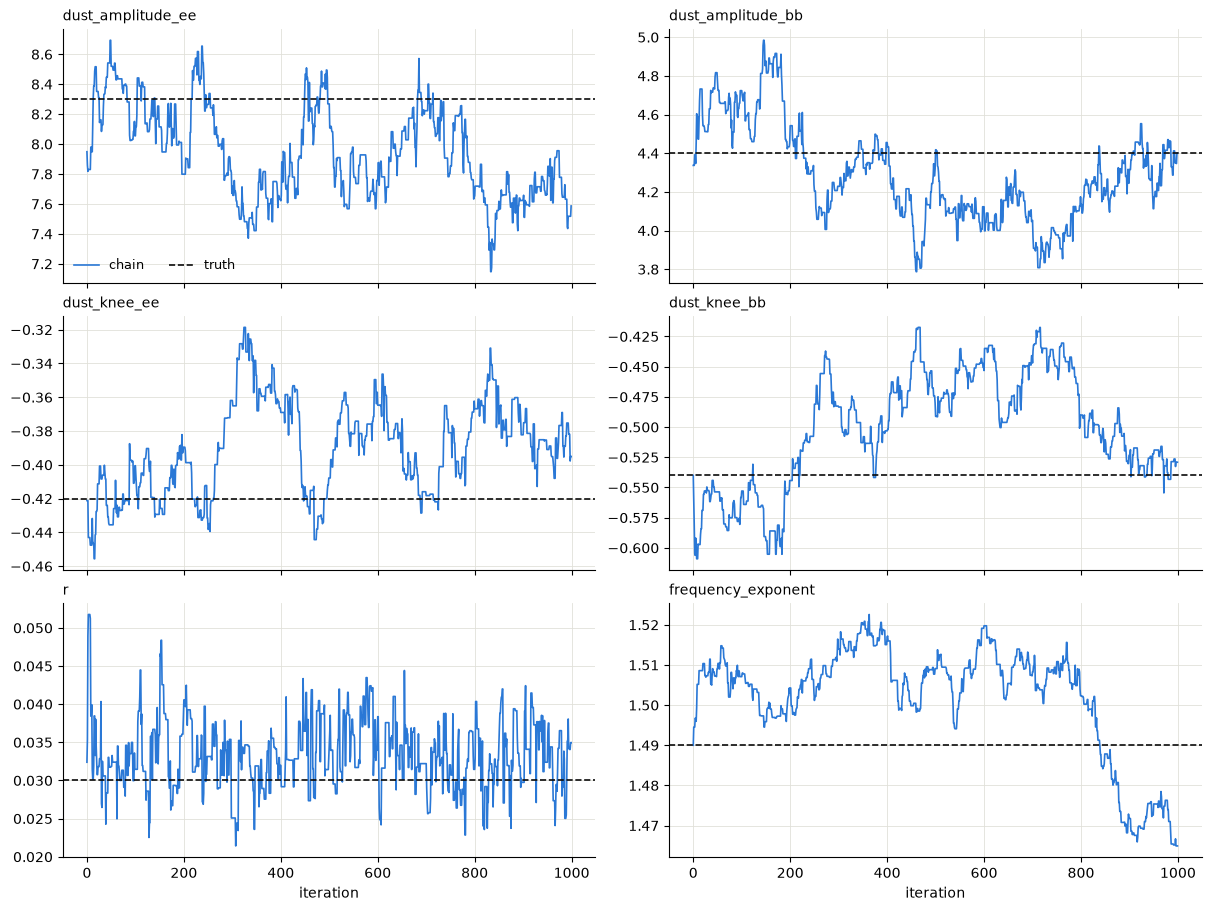

In [4]:
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
CHAIN_COLOR = "#2a78d6"

def style_axis(ax):
    ax.grid(color = GRID, lw = 0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig, axes = plt.subplots(3, 2, figsize = (12, 9), sharex = True, constrained_layout = True)
for ax, name in zip(axes.flat, PARAM_ORDER):
    ax.plot(sample_histories[name], color = CHAIN_COLOR, lw = 1.2, label = "chain")
    ax.axhline(true_params[name], color = INK, lw = 1.2, ls = "--", label = "truth")
    ax.set_title(name, loc = "left", fontsize = 10)
    style_axis(ax)
axes[0, 0].legend(frameon = False, fontsize = 9, ncols = 2)
for ax in axes[-1]:
    ax.set_xlabel("iteration")
plt.show()

## Log-posterior over time

The joint log-posterior of the fields and the parameters at the end of each iteration. It starts far below its typical value, because the dust field starts at zero, and settles within the first few iterations. The second panel drops those first iterations so the stationary part is visible.


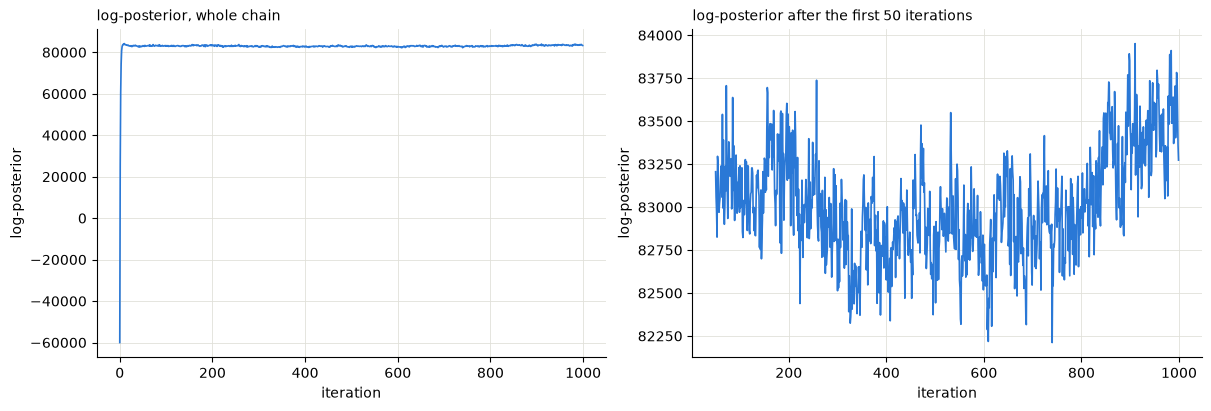

In [5]:
#iterations dropped from the start of the chain in everything below
burn_in = 50

fig, axes = plt.subplots(1, 2, figsize = (12, 4), constrained_layout = True)
axes[0].plot(logposterior_values, color = CHAIN_COLOR, lw = 1.2)
axes[0].set_title("log-posterior, whole chain", loc = "left", fontsize = 10)
iterations = np.arange(burn_in, num_iterations)
axes[1].plot(iterations, logposterior_values[burn_in:], color = CHAIN_COLOR, lw = 1.2)
axes[1].set_title(f"log-posterior after the first {burn_in} iterations", loc = "left", fontsize = 10)
for ax in axes:
    ax.set_xlabel("iteration")
    ax.set_ylabel("log-posterior")
    style_axis(ax)
plt.show()

## Autocorrelation and integrated autocorrelation time

Successive samples of a chain are correlated, so 1000 iterations are worth fewer than 1000 independent draws. The normalized autocorrelation function $\rho(t)$ measures the correlation between samples $t$ iterations apart, and the integrated autocorrelation time

$$\tau = 1 + 2\sum_{t \geq 1} \rho(t)$$

is the number of iterations per independent sample. The sum is truncated with Sokal's window (the first lag $M$ with $M \geq 5\tau(M)$), as implemented in `cmb_lensing.mcmc_diagnostics`. The effective sample size is the chain length divided by $\tau$.


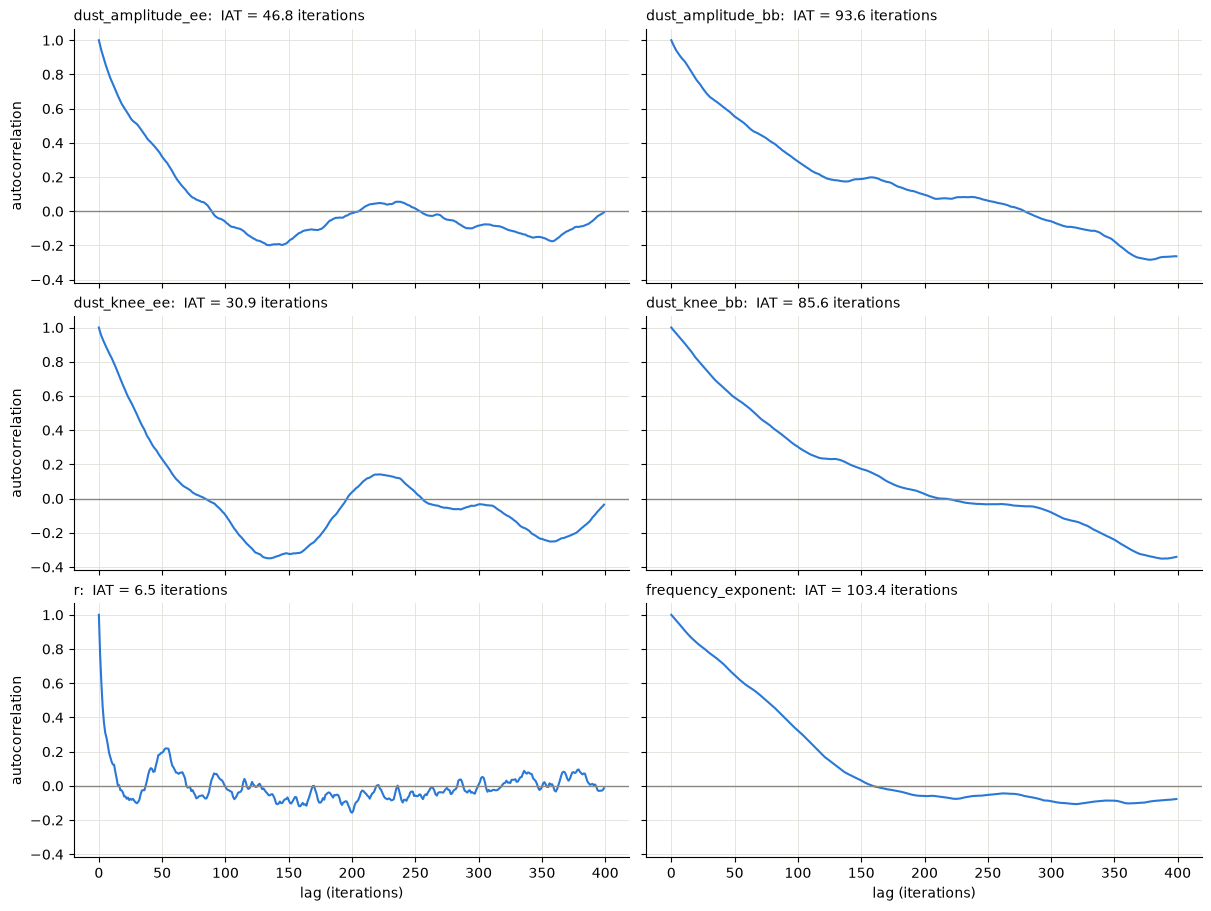

           parameter     IAT  effective samples (of 950)
   dust_amplitude_ee    46.8    20.3
   dust_amplitude_bb    93.6    10.2
        dust_knee_ee    30.9    30.8
        dust_knee_bb    85.6    11.1
                   r     6.5   146.8
  frequency_exponent   103.4     9.2


In [6]:
max_lag_shown = 400 
burnt_chains = {name: sample_histories[name][burn_in:] for name in PARAM_ORDER}
autocorrelations = {name: autocorrelation(burnt_chains[name]) for name in PARAM_ORDER}
iats = {name: integrated_autocorrelation_time(autocorrelations[name]) for name in PARAM_ORDER}

fig, axes = plt.subplots(3, 2, figsize = (12, 9), sharex = True, sharey = True,
                         constrained_layout = True)
for ax, name in zip(axes.flat, PARAM_ORDER):
    ax.plot(autocorrelations[name][:max_lag_shown], color = CHAIN_COLOR, lw = 1.5)
    ax.axhline(0, color = MUTED, lw = 1)
    ax.set_title(f"{name}:  IAT = {iats[name]:.1f} iterations", loc = "left", fontsize = 10)
    style_axis(ax)
for ax in axes[-1]:
    ax.set_xlabel("lag (iterations)")
for ax in axes[:, 0]:
    ax.set_ylabel("autocorrelation")
plt.show()

num_samples = num_iterations - burn_in
print(f"{'parameter':>20}  {'IAT':>6}  effective samples (of {num_samples})")
for name in PARAM_ORDER:
    print(f"{name:>20}  {iats[name]:6.1f}  {num_samples / iats[name]:6.1f}")

Only $r$ mixes quickly. The dust parameters and the frequency exponent have autocorrelation times of tens of iterations or more, so this chain holds only a handful of independent samples of them: it is long enough to show the sampler running, and too short for converged posteriors.

The dust parameters mix slowly because each is updated with the dust field held fixed, and the field in turn is redrawn with the parameters held fixed, so the pair can only move in small steps. Longer chains, several chains per map, or a reparametrization that moves the field and its amplitude together would all help.

## Recovered distributions against the truth

A Gaussian kernel density estimate (`scipy.stats.gaussian_kde`) turns each parameter's samples into a smooth distribution. The table gives the mean and standard deviation of that KDE and the z-score $(\text{mean} - \text{truth}) / \text{std}$, which for a correct sampler and a converged chain is a draw of order one. Both are integrals of the density over the plotted grid (`product_moments` from `cmb_lensing.chain_analysis`). The KDE's standard deviation is larger than that of the samples, because the KDE adds the width of its smoothing kernel; the fewer the samples, the wider the kernel.


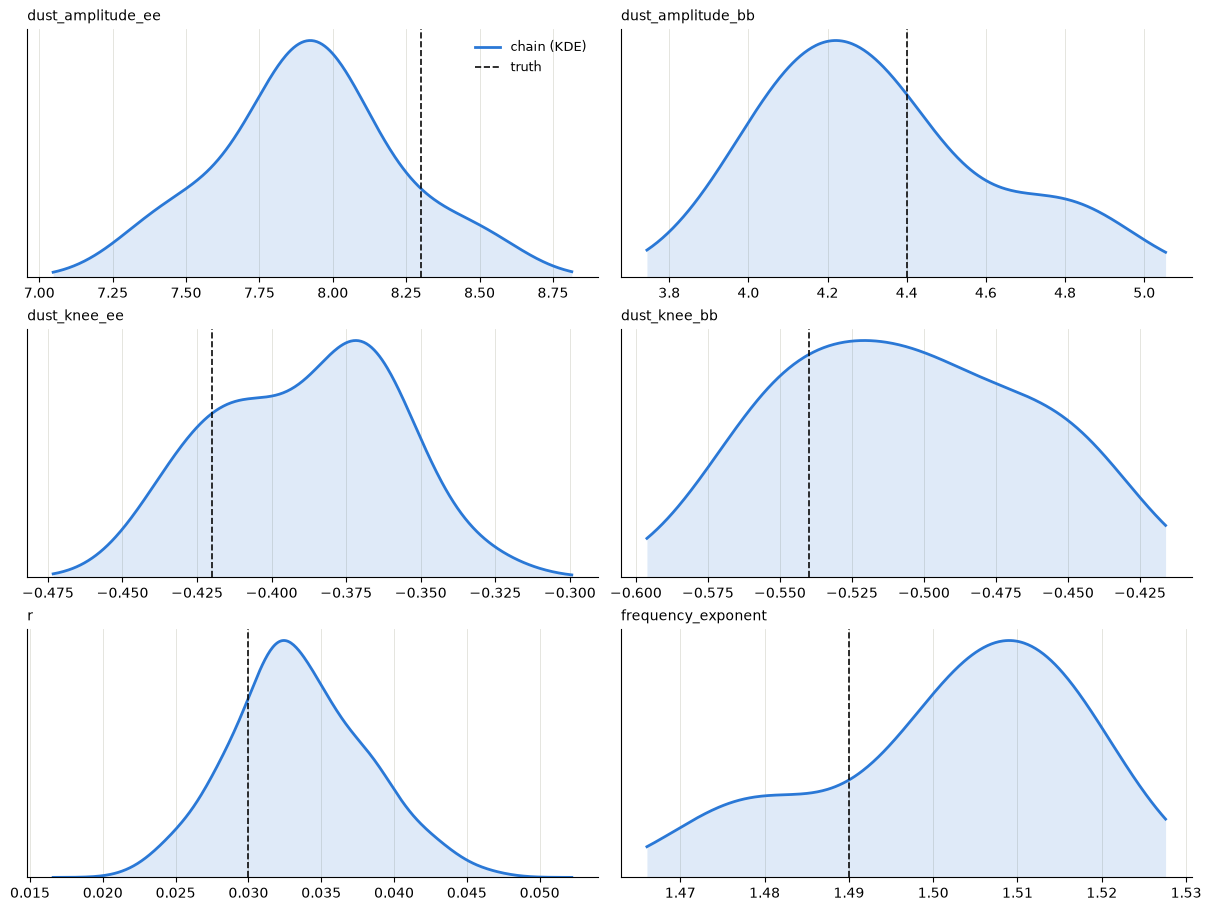

           parameter      truth       mean        std   z-score
   dust_amplitude_ee     8.3019     7.9186     0.3276     -1.17
   dust_amplitude_bb     4.4000     4.3232     0.2927     -0.26
        dust_knee_ee    -0.4200    -0.3886     0.0320     +0.98
        dust_knee_bb    -0.5400    -0.5063     0.0432     +0.78
                   r     0.0300     0.0335     0.0048     +0.73
  frequency_exponent     1.4900     1.5022     0.0146     +0.84


In [7]:
KDE_GRID_POINTS = 400
#how far past the samples' range the density is drawn, as a fraction of that range
KDE_GRID_PADDING = 0.25

fig, axes = plt.subplots(3, 2, figsize = (12, 9), constrained_layout = True)
summary = {}
for ax, name in zip(axes.flat, PARAM_ORDER):
    samples = burnt_chains[name][::int(iats[name])] #burnt and thinned samples

    low = min(samples.min(), true_params[name])
    high = max(samples.max(), true_params[name])
    padding = KDE_GRID_PADDING * (high - low)
    grid = np.linspace(low - padding, high + padding, KDE_GRID_POINTS)
    #the KDE on the grid, normalized there (product_pdf of a single density)
    density = product_pdf([gaussian_kde(samples)(grid)], grid)

    #mean and std of the KDE, integrated on the grid as in cmb_lensing's chain analysis
    mean, std = product_moments(density, grid)
    summary[name] = (mean, std, (mean - true_params[name]) / std)

    ax.plot(grid, density, color = CHAIN_COLOR, lw = 2, label = "chain (KDE)")
    ax.fill_between(grid, density, color = CHAIN_COLOR, alpha = 0.15, lw = 0)
    ax.axvline(true_params[name], color = INK, lw = 1.2, ls = "--", label = "truth")
    ax.set_title(name, loc = "left", fontsize = 10)
    ax.set_yticks([])
    ax.set_ylim(bottom = 0)
    style_axis(ax)
axes[0, 0].legend(frameon = False, fontsize = 9)
plt.show()

print(f"{'parameter':>20}  {'truth':>9}  {'mean':>9}  {'std':>9}  {'z-score':>8}")
for name in PARAM_ORDER:
    mean, std, z_score = summary[name]
    print(f"{name:>20}  {true_params[name]:9.4f}  {mean:9.4f}  {std:9.4f}  {z_score:+8.2f}")

Read these numbers with the autocorrelation times in mind.

- **$r$ is the one well-sampled parameter**, with about 80 effective samples, and it is recovered within a standard deviation of the truth in the presence of dust.
- **The dust amplitudes and slopes** are within a standard deviation too, but from 5 to 13 effective samples each, so their widths are rough.

So a 1000-iteration chain is a demonstration, not a measurement. The z-scores also describe one data realization and one chain: a real validation runs chains many autocorrelation times long over many maps and checks that the z-scores scatter around zero with unit width. That has not been done yet.

With those caveats, the outcome is what a self-consistent Gaussian analysis should give, and it is the optimistic baseline described at the top. The same sampler pointed at non-Gaussian dust would be using the wrong model, and that comparison is the next step.
